In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "1"

In [2]:
from functools import partial
from pathlib import Path

import keras
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import tensorflow as tf
from tqdm.auto import tqdm
import wandb
from wandb.integration.keras import WandbMetricsLogger

2024-09-09 08:12:38.147567: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-09-09 08:12:38.147596: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-09-09 08:12:38.148709: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-09-09 08:12:38.648463: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT
/home/alex/inatVisionTrainingMain/inatVisionTraining/venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html

In [3]:
def make_net(n_classes):
    base_arch = keras.applications.MobileNetV3Large
    base_model = base_arch(
        input_shape=[224, 224, 3],
        weights="imagenet",
        include_top=False
    )
    for layer in base_model.layers:
        if isinstance(layer, keras.layers.BatchNormalization):
            layer.trainable = False
        else:
            layer.trainable = True
        
    model = keras.Sequential([
        base_model,
        keras.layers.GlobalAveragePooling2D(keepdims=True),
        keras.layers.Dropout(0.2),
        keras.layers.Conv2D(64, [1, 1], name="svd_u"),
        keras.layers.Conv2D(n_classes, [1, 1], name="logits"),
        keras.layers.Reshape([n_classes], name="reshaped_logits"),
    ])

    return model

# make dataset

In [4]:
export_dir = Path("/data-ssd/alex/datasets/vision-export-20230412214019-Mammalia-40151/")

In [5]:
tax = pd.read_csv(export_dir / "taxonomy.csv")
leaf_tax = tax[~tax.leaf_class_id.isna()]
num_classes = len(leaf_tax)
print(f"{num_classes} classes")

1203 classes


In [6]:
train_augmented = pd.read_csv(export_dir / "train_data_augmented.csv")

In [7]:
!ls {export_dir}

all_taxa.csv	  taxonomy_visual.txt	    train_data.csv
iconic_taxa.csv   test_data.csv		    val_cleaned.csv
spatial_data.csv  train_cleaned.csv	    val_data.csv
taxonomy.csv	  train_data_augmented.csv


In [8]:
train_augmented.sample(3)

,photo_id,extension,taxon_id,leaf_class_id
1013498,104986800,jpeg,42223,812
3436898,352614466,jpeg,42223,812
3079862,325421427,jpg,41708,204


In [9]:
import hashlib
import os

def path_for_photo_id(base_dir, photo_id):
    msg = str(photo_id).encode('utf-8')
    m = hashlib.sha256()
    m.update(msg)
    hashed = m.hexdigest()
    filename = '{}.jpg'.format(photo_id)
    photo_paths = [base_dir, hashed[0:2], hashed[2:4], filename]
    return os.path.join(*photo_paths)

In [10]:
tqdm.pandas()

In [11]:
train_augmented["filename"] = train_augmented.progress_apply(lambda x: path_for_photo_id("/data-ssd2/alex/images", x.photo_id), axis=1)

100%|██████████████████████████████████████████████████████████████████████████| 4128118/4128118 [00:28<00:00, 142686.03it/s]


In [12]:
len(train_augmented)

4128118

In [13]:
train_augmented["file_exists"] = train_augmented.filename.progress_apply(lambda x: os.path.exists(x))

100%|██████████████████████████████████████████████████████████████████████████| 4128118/4128118 [00:37<00:00, 111127.05it/s]


In [14]:
train_augmented["file_exists"].value_counts()

file_exists
True     4128108
False         10
Name: count, dtype: int64

In [15]:
train_augmented.taxon_id.value_counts()

taxon_id
42223     303951
46017     269303
41663     151181
42051     128730
43111     128444
           ...  
42369          1
846232         1
44179          1
42314          1
43231          1
Name: count, Length: 1196, dtype: int64

In [16]:
tax[tax.taxon_id==42223]

,parent_taxon_id,taxon_id,rank_level,leaf_class_id,iconic_class_id,spatial_class_id,name
1834,42219.0,42223,10.0,812.0,0.0,812.0,Odocoileus virginianus


In [17]:
200 * 1_000

200000

In [18]:
train_augmented = train_augmented[train_augmented.file_exists]

In [19]:
train_cleaned = pd.read_csv(
    export_dir / "train_cleaned.csv",
    usecols=["filename", "leaf_class_id"],
)

In [20]:
train_cleaned = train_cleaned[["filename", "leaf_class_id"]]
train_augmented = train_augmented[["filename", "leaf_class_id"]]
train_df = pd.concat([train_cleaned, train_augmented])
train_df.drop_duplicates(subset=["filename"], inplace=True, keep=False)

In [21]:
#train_df[train_df.filename=="/data-ssd2/alex/images/c9/c9/299813711.jpg"]

In [22]:
train_df.leaf_class_id.value_counts()

leaf_class_id
812     304535
504     270202
409     152075
798     129621
957     129420
         ...  
1175        68
1165        55
1154        55
1196        53
1152        53
Name: count, Length: 1203, dtype: int64

In [23]:
max_sample_size = 1_000

train_df = train_df.sample(frac=1)
train_df_sample = train_df.groupby("leaf_class_id").head(max_sample_size)

In [24]:
train_df_sample.leaf_class_id.value_counts()

leaf_class_id
190     1000
1049    1000
401     1000
523     1000
431     1000
        ... 
1175      68
1165      55
1154      55
1196      53
1152      53
Name: count, Length: 1203, dtype: int64

In [25]:
train_cleaned.leaf_class_id.value_counts()

leaf_class_id
1080    1000
261     1000
667     1000
276     1000
661     1000
        ... 
1106      51
423       51
572       50
596       50
315       50
Name: count, Length: 1203, dtype: int64

# baseline

In [26]:
BATCH_SIZE=128
IMAGE_SIZE=[224, 224]

In [27]:
def _flip(x, y):
    x = tf.image.random_flip_left_right(x)
    return x, y

def _random_crop(x, y):
    bbox = tf.constant([0.0, 0.0, 1.0, 1.0], dtype=tf.float32, shape=[1, 1, 4])
    begin, size, bbox_for_draw = tf.image.sample_distorted_bounding_box(
        tf.shape(x),
        bounding_boxes=bbox,
        area_range=(0.08, 1.0),
        aspect_ratio_range=(0.75, 1.33),
        max_attempts=100,
        min_object_covered=0.1,
    )
    x = tf.slice(x, begin, size)
    return x, y

def _color(x, y):
    x = tf.image.random_hue(x, 0.08)
    x = tf.image.random_saturation(x, 0.6, 1.6)
    x = tf.image.random_brightness(x, 0.05)
    x = tf.image.random_contrast(x, 0.7, 1.3)
    return x, y

# mobilenets v3 expects images in range 0,255
def _decode_img(img):
    img = tf.image.decode_jpeg(img, channels=3)
    return img

def _process(filepath, label, num_classes):
    img = tf.io.read_file(filepath)
    img = _decode_img(img)
    label = tf.one_hot(label, num_classes)
    return img, label

def make_dataset(dataframe, BATCH_SIZE, IMAGE_SIZE, repeat_forever=True, augment=False):
    num_examples = len(dataframe)
    ds = tf.data.Dataset.from_tensor_slices(
        (dataframe["filename"], dataframe["leaf_class_id"])
    )
    ds = ds.shuffle(buffer_size=10_000, reshuffle_each_iteration=True)
    process_partial = partial(_process, num_classes=num_classes)
    ds = ds.map(process_partial, num_parallel_calls=tf.data.AUTOTUNE)

    if augment:
        ds = ds.map(lambda x, y: _flip(x, y), num_parallel_calls=tf.data.AUTOTUNE)
        ds = ds.map(lambda x, y: _random_crop(x, y), num_parallel_calls=tf.data.AUTOTUNE)
        ds = ds.map(lambda x, y: (tf.cast(x, tf.float32), y), num_parallel_calls=tf.data.AUTOTUNE)
        ds = ds.map(lambda x, y: (x / 255.0, y), num_parallel_calls=tf.data.AUTOTUNE)
        ds = ds.map(lambda x, y: _color(x, y), num_parallel_calls=tf.data.AUTOTUNE)
        ds = ds.map(lambda x, y: (tf.clip_by_value(x, 0, 1), y), num_parallel_calls=tf.data.AUTOTUNE)
        ds = ds.map(lambda x, y: (x * 255.0, y), num_parallel_calls=tf.data.AUTOTUNE)
        ds = ds.map(lambda x, y: (tf.cast(x, tf.uint8), y), num_parallel_calls=tf.data.AUTOTUNE)

        
        ds = ds.map(lambda x, y: (tf.image.resize(x, IMAGE_SIZE), y), num_parallel_calls=tf.data.AUTOTUNE)

    else:
        # no augments
        ds = ds.map(lambda x, y: (tf.image.central_crop(x, 0.875), y), num_parallel_calls=tf.data.AUTOTUNE)
        ds = ds.map(lambda x, y: (tf.image.resize(x, IMAGE_SIZE), y), num_parallel_calls=tf.data.AUTOTUNE)
        
    ds = ds.batch(BATCH_SIZE)
    if repeat_forever:
        ds = ds.repeat()
    ds = ds.prefetch(buffer_size=tf.data.AUTOTUNE)
    
    return ds, num_examples

In [28]:
train_cleaned = pd.read_csv(export_dir / "train_cleaned.csv")
train_cleaned = train_cleaned.sample(frac=1)
val_cleaned = pd.read_csv(export_dir / "val_cleaned.csv")
val_cleaned = val_cleaned.sample(frac=1)

(train_ds, num_train_examples) = make_dataset(train_cleaned, BATCH_SIZE, IMAGE_SIZE)
(val_ds, num_val_examples) = make_dataset(val_cleaned, BATCH_SIZE, IMAGE_SIZE)

In [29]:
# mixed precision training
policy = keras.mixed_precision.Policy("mixed_float16")
keras.mixed_precision.set_global_policy(policy)

INFO:tensorflow:Mixed precision compatibility check (mixed_float16): OK
Your GPU will likely run quickly with dtype policy mixed_float16 as it has compute capability of at least 7.0. Your GPU: NVIDIA RTX 6000 Ada Generation, compute capability 8.9


In [30]:
model = make_net(num_classes)

In [31]:
model.compile(
    loss=keras.losses.CategoricalCrossentropy(from_logits=True),
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    metrics=["accuracy"],
)

In [32]:
STEPS_PER_EPOCH = int(np.ceil(num_train_examples / BATCH_SIZE))
VAL_STEPS_PER_EPOCH = int(np.ceil(num_val_examples / BATCH_SIZE))

In [33]:
wandb.init(
    project="mammals-new",
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    validation_steps=VAL_STEPS_PER_EPOCH,
    epochs=2,
    steps_per_epoch=STEPS_PER_EPOCH,
    callbacks=[WandbMetricsLogger(log_freq=100)],
)

wandb.finish()

Failed to detect the name of this notebook, you can set it manually with the WANDB_NOTEBOOK_NAME environment variable to enable code saving.
wandb: Currently logged in as: alexshepard (alexshepard-personal). Use `wandb login --relogin` to force relogin


Epoch 1/2


I0000 00:00:1725894943.903813 1937698 device_compiler.h:186] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


5098/5098 [==============================] - 313s 59ms/step - loss: 3.8944 - accuracy: 0.2234 - val_loss: 3.0751 - val_accuracy: 0.3200
Epoch 2/2
5098/5098 [==============================] - 298s 58ms/step - loss: 2.6570 - accuracy: 0.3845 - val_loss: 2.6560 - val_accuracy: 0.3878


batch/accuracy,▁▁▂▂▂▃▃▃▃▄▄▄▄▄▄▅▅▅▅▅▇▇▇▇▇▇▇█████████████
batch/batch_step,▁▁▁▁▂▂▂▂▂▃▃▃▃▃▃▄▄▄▄▄▅▅▅▅▅▅▆▆▆▆▆▇▇▇▇▇▇███
batch/learning_rate,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
batch/loss,██▇▆▆▅▅▅▄▄▄▄▄▄▃▃▃▃▃▃▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
epoch/accuracy,▁█
epoch/epoch,▁█
epoch/learning_rate,▁▁
epoch/loss,█▁
epoch/val_accuracy,▁█
epoch/val_loss,█▁
batch/accuracy,0.38373


# ok let's do with a custom training loop for comparison

skipping this for mammals cuz it was so slow even with galliformes

In [34]:
# train_cleaned = pd.read_csv(export_dir / "train_cleaned.csv")
# train_cleaned = train_cleaned.sample(frac=1)
# val_cleaned = pd.read_csv(export_dir / "val_cleaned.csv")
# val_cleaned = val_cleaned.sample(frac=1)

# (train_ds, num_train_examples) = make_dataset(train_cleaned, BATCH_SIZE, IMAGE_SIZE, repeat_forever=False)
# (val_ds, num_val_examples) = make_dataset(val_cleaned, BATCH_SIZE, IMAGE_SIZE, repeat_forever=False)

# STEPS_PER_EPOCH = int(np.ceil(num_train_examples / BATCH_SIZE))
# VAL_STEPS_PER_EPOCH = int(np.ceil(num_val_examples / BATCH_SIZE))

In [35]:
# loss = keras.losses.CategoricalCrossentropy(from_logits=True)
# optimizer = keras.optimizers.Adam(learning_rate=1e-4)
# accuracy = keras.metrics.Accuracy()
# model = make_net(num_classes)

# for epoch in range(2):
#     print(f"epoch {epoch+1}")
#     losses = []
#     with tqdm(total=STEPS_PER_EPOCH as pbar:
#         for step, (x, y) in enumerate(train_ds):
#             with tf.GradientTape() as tape:
#                 yhat = model(x, training=True)
#                 batch_loss = loss(y, yhat)
#                 grads = tape.gradient(batch_loss, model.trainable_weights)
#                 optimizer.apply_gradients(zip(grads, model.trainable_weights))
#             pbar.update()
#             losses.append(batch_loss)
#         print(f"epoch loss {np.mean(losses)}")


In [36]:
# model.compile(
#     loss=loss,
#     metrics=["accuracy"]
# )

In [37]:
# model.evaluate(val_ds)

# ok let's try one dataset per epoch (stupid but w/e)

In [ ]:
wandb.init(
    project="mammals-new",
)

baseline_model = make_net(num_classes)
loss = keras.losses.CategoricalCrossentropy(from_logits=True)
baseline_model.compile(
    loss=loss,
    metrics=["accuracy"],
    optimizer=keras.optimizers.Adam(1e-4),
)

baseline_history = {
    "loss": [],
    "accuracy": [],
    "val_loss": [],
    "val_accuracy": [],
}

NUM_EPOCHS = 10

for epoch in range(NUM_EPOCHS):
    print(f"epoch {epoch}")
    train_cleaned = pd.read_csv(export_dir / "train_cleaned.csv")
    train_cleaned = train_cleaned.sample(frac=1)
    val_cleaned = pd.read_csv(export_dir / "val_cleaned.csv")
    val_cleaned = val_cleaned.sample(frac=1)

    (train_ds, num_train_examples) = make_dataset(train_cleaned, BATCH_SIZE, IMAGE_SIZE, repeat_forever=False)
    (val_ds, num_val_examples) = make_dataset(val_cleaned, BATCH_SIZE, IMAGE_SIZE, repeat_forever=False)

    STEPS_PER_EPOCH = int(np.ceil(num_train_examples / BATCH_SIZE))
    VAL_STEPS_PER_EPOCH = int(np.ceil(num_val_examples / BATCH_SIZE))
    
    epoch_hist = baseline_model.fit(
        train_ds,
        steps_per_epoch=STEPS_PER_EPOCH,
        validation_data=val_ds,
        validation_steps=VAL_STEPS_PER_EPOCH,
        epochs=epoch+1,
        initial_epoch=epoch,
        callbacks=[WandbMetricsLogger(log_freq=100)],
    )
    
    baseline_history["loss"].append(epoch_hist.history["loss"][-1])
    baseline_history["accuracy"].append(epoch_hist.history["accuracy"][-1])
    baseline_history["val_loss"].append(epoch_hist.history["val_loss"][-1])
    baseline_history["val_accuracy"].append(epoch_hist.history["val_accuracy"][-1])

wandb.finish()

epoch 0
5098/5098 [==============================] - 294s 56ms/step - loss: 3.8999 - accuracy: 0.2250 - val_loss: 3.0639 - val_accuracy: 0.3232
epoch 1
Epoch 2/2
5098/5098 [==============================] - 287s 56ms/step - loss: 2.6538 - accuracy: 0.3856 - val_loss: 2.6346 - val_accuracy: 0.3880
epoch 2
Epoch 3/3
5098/5098 [==============================] - 289s 57ms/step - loss: 2.2752 - accuracy: 0.4533 - val_loss: 2.4170 - val_accuracy: 0.4277
epoch 3
Epoch 4/4
5098/5098 [==============================] - 288s 57ms/step - loss: 2.0336 - accuracy: 0.4992 - val_loss: 2.3407 - val_accuracy: 0.4444
epoch 4
Epoch 5/5
5098/5098 [==============================] - 288s 57ms/step - loss: 1.8512 - accuracy: 0.5364 - val_loss: 2.3220 - val_accuracy: 0.4531
epoch 5
Epoch 6/6
5098/5098 [==============================] - 287s 56ms/step - loss: 1.7031 - accuracy: 0.5652 - val_loss: 2.2732 - val_accuracy: 0.4661
epoch 6
Epoch 7/7
5098/5098 [==============================] - 288s 56ms/step - loss: 

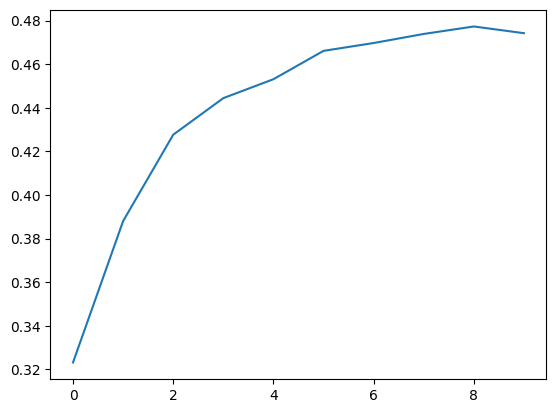

In [35]:
plt.plot(baseline_history["val_accuracy"])

# ok now let's sample from larger dataset

In [36]:
wandb.init(
    project="mammals-new",
)


train_plus_aug_df = pd.concat([train_cleaned, train_augmented])
max_sample_size = 1_000

model_1k_sample = make_net(num_classes)
model_1k_sample.compile(
    loss=loss,
    metrics=["accuracy"],
    optimizer=keras.optimizers.Adam(1e-4),
)

history_1k = {
    "loss": [],
    "accuracy": [],
    "val_loss": [],
    "val_accuracy": [],
}

NUM_EPOCHS = 10
for epoch in range(NUM_EPOCHS):
    print(f"epoch {epoch}")
    
    train_plus_aug_df = train_plus_aug_df.sample(frac=1)
    train_df_sample = train_plus_aug_df.groupby("leaf_class_id").head(max_sample_size)
    train_df_sample = train_df_sample.sample(frac=1)
    
    val_cleaned = pd.read_csv(export_dir / "val_cleaned.csv")
    val_cleaned = val_cleaned.sample(frac=1)
    
    (train_ds, num_train_examples) = make_dataset(train_df_sample, BATCH_SIZE, IMAGE_SIZE, repeat_forever=False)
    (val_ds, num_val_examples) = make_dataset(val_cleaned, BATCH_SIZE, IMAGE_SIZE, repeat_forever=False)

    STEPS_PER_EPOCH = int(np.ceil(num_train_examples / BATCH_SIZE))
    VAL_STEPS_PER_EPOCH = int(np.ceil(num_val_examples / BATCH_SIZE))
    
    epoch_hist = model_1k_sample.fit(
        train_ds,
        steps_per_epoch=STEPS_PER_EPOCH,
        validation_data=val_ds,
        validation_steps=VAL_STEPS_PER_EPOCH,
        epochs=epoch+1,
        initial_epoch=epoch,
        callbacks=[WandbMetricsLogger(log_freq=100)],
    )
    history_1k["loss"].append(epoch_hist.history["loss"][-1])
    history_1k["accuracy"].append(epoch_hist.history["accuracy"][-1])
    history_1k["val_loss"].append(epoch_hist.history["val_loss"][-1])
    history_1k["val_accuracy"].append(epoch_hist.history["val_accuracy"][-1])

wandb.finish()

epoch 0
6098/6098 [==============================] - 355s 57ms/step - loss: 3.9786 - accuracy: 0.2062 - val_loss: 2.9278 - val_accuracy: 0.3299
epoch 1
Epoch 2/2
6098/6098 [==============================] - 347s 57ms/step - loss: 2.7916 - accuracy: 0.3588 - val_loss: 2.4942 - val_accuracy: 0.4041
epoch 2
Epoch 3/3
6098/6098 [==============================] - 347s 57ms/step - loss: 2.4434 - accuracy: 0.4213 - val_loss: 2.2994 - val_accuracy: 0.4407
epoch 3
Epoch 4/4
6098/6098 [==============================] - 347s 57ms/step - loss: 2.2389 - accuracy: 0.4606 - val_loss: 2.1976 - val_accuracy: 0.4635
epoch 4
Epoch 5/5
6098/6098 [==============================] - 348s 57ms/step - loss: 2.0896 - accuracy: 0.4894 - val_loss: 2.1176 - val_accuracy: 0.4810
epoch 5
Epoch 6/6
6098/6098 [==============================] - 347s 57ms/step - loss: 1.9696 - accuracy: 0.5148 - val_loss: 2.0799 - val_accuracy: 0.4846
epoch 6
Epoch 7/7
6098/6098 [==============================] - 349s 57ms/step - loss: 

batch/accuracy,▁▂▂▃▅▅▅▅▆▆▆▆▆▆▆▆▇▇▇▇▇▇▇▇▇▇▇▇████████████
batch/batch_step,▂▃▅▇▁▃▅▇▁▃▅▇▂▄▅▇▁▃▅▇▁▃▅▇▂▄▆▇▁▃▅▇▂▄▆█▂▄▆█
batch/learning_rate,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
batch/loss,█▇▅▅▃▃▃▃▂▂▂▂▂▂▂▂▂▂▂▂▁▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
epoch/accuracy,▁▄▅▆▆▇▇▇██
epoch/epoch,▁▂▃▃▄▅▆▆▇█
epoch/learning_rate,▁▁▁▁▁▁▁▁▁▁
epoch/loss,█▄▃▃▂▂▂▁▁▁
epoch/val_accuracy,▁▄▅▆▇▇▇███
epoch/val_loss,█▅▃▂▂▁▁▁▁▁
batch/accuracy,0.58013


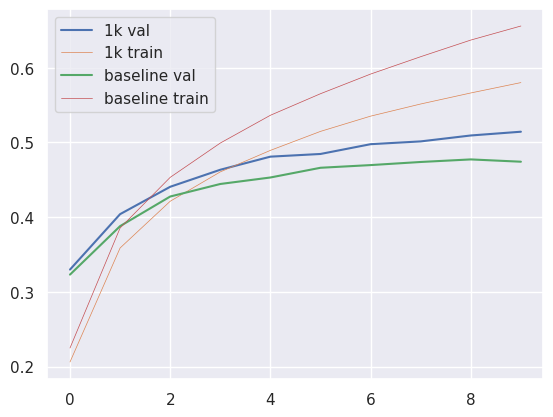

In [48]:
import seaborn as sns; sns.set()

sns.lineplot(history_1k["val_accuracy"], label="1k val")
sns.lineplot(history_1k["accuracy"], label="1k train", lw=0.5)

sns.lineplot(baseline_history["val_accuracy"], label="baseline val")
sns.lineplot(baseline_history["accuracy"], label="baseline train", lw=0.5)

plt.legend()
plt.show()


# let's try with a sample size of 500

In [50]:
wandb.init(
    project="mammals-new",
)

train_plus_aug_df = pd.concat([train_cleaned, train_augmented])
max_sample_size = 500

model_500 = make_net(num_classes)
model_500.compile(
    loss=loss,
    metrics=["accuracy"],
    optimizer=keras.optimizers.Adam(1e-4),
)

history_500 = {
    "loss": [],
    "accuracy": [],
    "val_loss": [],
    "val_accuracy": [],
}

NUM_EPOCHS = 20
for epoch in range(NUM_EPOCHS):
    print(f"epoch {epoch}")
    
    train_plus_aug_df = train_plus_aug_df.sample(frac=1)
    train_df_sample = train_plus_aug_df.groupby("leaf_class_id").head(max_sample_size)
    train_df_sample = train_df_sample.sample(frac=1)
    
    val_cleaned = pd.read_csv(export_dir / "val_cleaned.csv")
    val_cleaned = val_cleaned.sample(frac=1)
    
    (train_ds, num_train_examples) = make_dataset(train_df_sample, BATCH_SIZE, IMAGE_SIZE, repeat_forever=False)
    (val_ds, num_val_examples) = make_dataset(val_cleaned, BATCH_SIZE, IMAGE_SIZE, repeat_forever=False)

    STEPS_PER_EPOCH = int(np.ceil(num_train_examples / BATCH_SIZE))
    VAL_STEPS_PER_EPOCH = int(np.ceil(num_val_examples / BATCH_SIZE))
    
    epoch_hist = model_500.fit(
        train_ds,
        steps_per_epoch=STEPS_PER_EPOCH,
        validation_data=val_ds,
        validation_steps=VAL_STEPS_PER_EPOCH,
        epochs=epoch+1,
        initial_epoch=epoch,
        callbacks=[WandbMetricsLogger(log_freq=100)],
    )
    history_500["loss"].append(epoch_hist.history["loss"][-1])
    history_500["accuracy"].append(epoch_hist.history["accuracy"][-1])
    history_500["val_loss"].append(epoch_hist.history["val_loss"][-1])
    history_500["val_accuracy"].append(epoch_hist.history["val_accuracy"][-1])

wandb.finish()

epoch 0
3788/3788 [==============================] - 224s 57ms/step - loss: 4.5048 - accuracy: 0.1450 - val_loss: 3.2595 - val_accuracy: 0.2684
epoch 1
Epoch 2/2
3788/3788 [==============================] - 216s 57ms/step - loss: 3.1628 - accuracy: 0.2942 - val_loss: 2.7799 - val_accuracy: 0.3479
epoch 2
Epoch 3/3
3788/3788 [==============================] - 215s 57ms/step - loss: 2.7598 - accuracy: 0.3620 - val_loss: 2.5437 - val_accuracy: 0.3922
epoch 3
Epoch 4/4
3788/3788 [==============================] - 216s 57ms/step - loss: 2.5221 - accuracy: 0.4050 - val_loss: 2.4217 - val_accuracy: 0.4185
epoch 4
Epoch 5/5
3788/3788 [==============================] - 215s 57ms/step - loss: 2.3454 - accuracy: 0.4393 - val_loss: 2.3125 - val_accuracy: 0.4388
epoch 5
Epoch 6/6
3788/3788 [==============================] - 215s 57ms/step - loss: 2.2100 - accuracy: 0.4664 - val_loss: 2.2526 - val_accuracy: 0.4510
epoch 6
Epoch 7/7
3788/3788 [==============================] - 215s 57ms/step - loss: 

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



3788/3788 [==============================] - 215s 57ms/step - loss: 1.4490 - accuracy: 0.6328 - val_loss: 2.1808 - val_accuracy: 0.4981
epoch 18
Epoch 19/19
3788/3788 [==============================] - 215s 57ms/step - loss: 1.4132 - accuracy: 0.6407 - val_loss: 2.1797 - val_accuracy: 0.4975
epoch 19
Epoch 20/20
3788/3788 [==============================] - 215s 57ms/step - loss: 1.3833 - accuracy: 0.6486 - val_loss: 2.1859 - val_accuracy: 0.5030


batch/accuracy,▁▂▄▄▅▅▅▅▆▆▆▆▆▆▆▆▇▇▇▇▇▇▇▇▇▇▇▇█▇██████████
batch/batch_step,▂▅▁▆▁▆▂▅▂▅▃▆▁▆▂▆▂▅▃▆▃▆▃▆▂▇▃▇▃▆▃▆▄▇▃▇▃█▃█
batch/learning_rate,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
batch/loss,█▆▄▄▃▃▃▃▂▂▂▂▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
epoch/accuracy,▁▃▄▅▅▅▆▆▆▇▇▇▇▇▇█████
epoch/epoch,▁▁▂▂▂▃▃▄▄▄▅▅▅▆▆▇▇▇██
epoch/learning_rate,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
epoch/loss,█▅▄▄▃▃▃▂▂▂▂▂▂▂▁▁▁▁▁▁
epoch/val_accuracy,▁▃▅▅▆▆▇▇▇▇▇█████████
epoch/val_loss,█▅▄▃▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁
batch/accuracy,0.64877


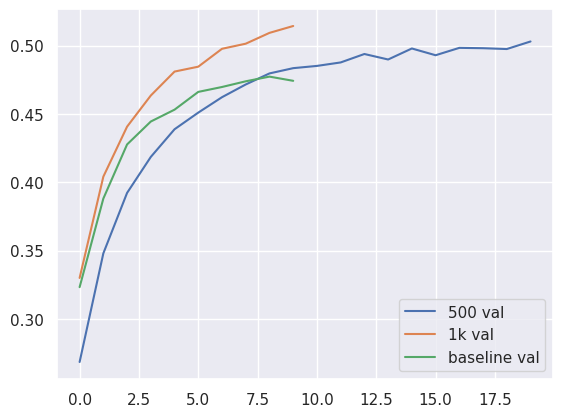

In [53]:
sns.lineplot(history_500["val_accuracy"], label="500 val")
sns.lineplot(history_1k["val_accuracy"], label="1k val")
sns.lineplot(baseline_history["val_accuracy"], label="baseline val")

plt.legend()
plt.show()

# ok let's do pre class metrics with the test dataset

In [57]:
test_cleaned = pd.read_csv(export_dir / "test_cleaned.csv")
num_test_examples = len(test_cleaned)
test_ds = tf.data.Dataset.from_tensor_slices(
    (test_cleaned["filename"], test_cleaned["leaf_class_id"])
)
process_partial = partial(_process, num_classes=num_classes)
test_ds = test_ds.map(process_partial)
test_ds = test_ds.map(lambda x, y: (tf.image.central_crop(x, 0.875), y))
test_ds = test_ds.map(lambda x, y: (tf.image.resize(x, IMAGE_SIZE), y))
test_ds = test_ds.batch(BATCH_SIZE)

In [58]:
baseline_test_preds = baseline_model.predict(test_ds)

388/388 [==============================] - 8s 20ms/step


In [59]:
yhats = baseline_test_preds.argmax(axis=1)
ys = test_cleaned["leaf_class_id"].values
results = pd.DataFrame({
    "y": ys,
    "yhat": yhats,
})
(results.y == results.yhat).sum() / len(results)

0.476862950502629

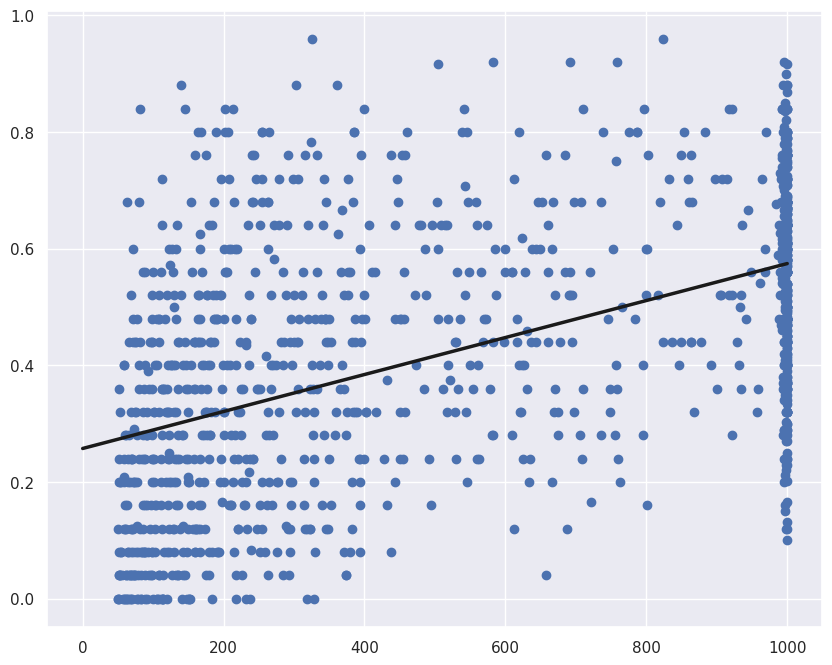

In [60]:
subsets = []
for leaf_class_id in range(num_classes):
    num_train_classes = len(train_cleaned[train_cleaned.leaf_class_id==leaf_class_id])
    subset = results[(results.y == leaf_class_id)]
    subset_acc = (subset.y == subset.yhat).sum() / len(subset)
    subsets.append( (num_train_classes, subset_acc) )

(train_classes, accs) = list(zip(*subsets))
fig, ax = plt.subplots(figsize=(10, 8))
ax.scatter(train_classes, accs)
baseline_b, baseline_a = np.polyfit(train_classes, accs, deg=1)
xseq = np.linspace(0, 1_000, num=100)
ax.plot(xseq, baseline_a + baseline_b * xseq, color="k", lw=2.5)
plt.show()

In [61]:
test_preds_1k = model_1k_sample.predict(test_ds)

388/388 [==============================] - 8s 20ms/step


In [62]:
yhats = test_preds_1k.argmax(axis=1)
ys = test_cleaned["leaf_class_id"].values
results = pd.DataFrame({
    "y": ys,
    "yhat": yhats,
})
(results.y == results.yhat).sum() / len(results)

0.5738431475251314

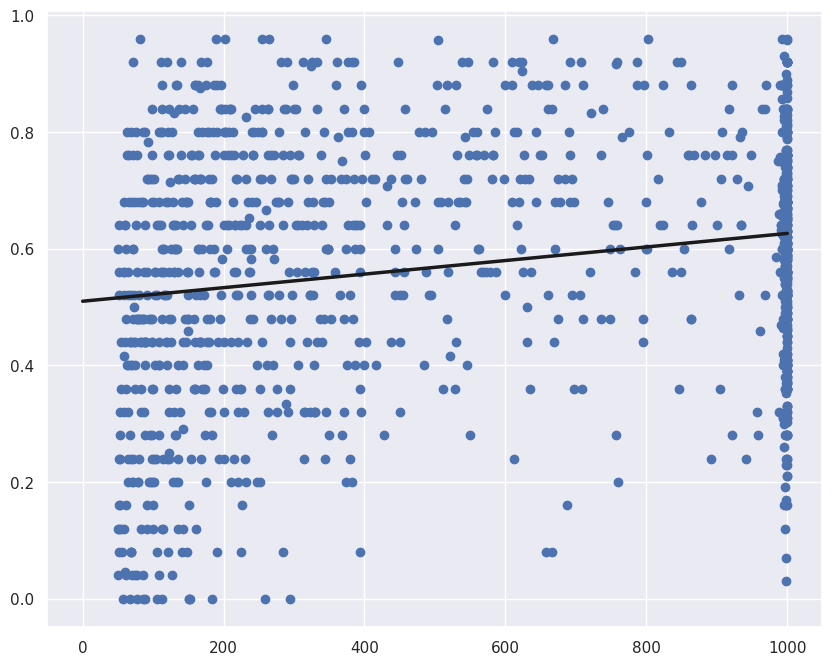

In [63]:
subsets = []
for leaf_class_id in range(num_classes):
    num_train_classes = len(train_cleaned[train_cleaned.leaf_class_id==leaf_class_id])
    subset = results[(results.y == leaf_class_id)]
    subset_acc = (subset.y == subset.yhat).sum() / len(subset)
    subsets.append( (num_train_classes, subset_acc) )

(train_classes, accs) = list(zip(*subsets))
fig, ax = plt.subplots(figsize=(10, 8))
ax.scatter(train_classes, accs)
b_1k, a_1k = np.polyfit(train_classes, accs, deg=1)
xseq = np.linspace(0, 1_000, num=100)
ax.plot(xseq, a_1k + b_1k * xseq, color="k", lw=2.5)
plt.show()

In [64]:
test_preds_500 = model.predict(test_ds)

yhats = test_preds_500.argmax(axis=1)
ys = test_cleaned["leaf_class_id"].values
results = pd.DataFrame({
    "y": ys,
    "yhat": yhats,
})
(results.y == results.yhat).sum() / len(results)

388/388 [==============================] - 8s 20ms/step


0.39434718668788654

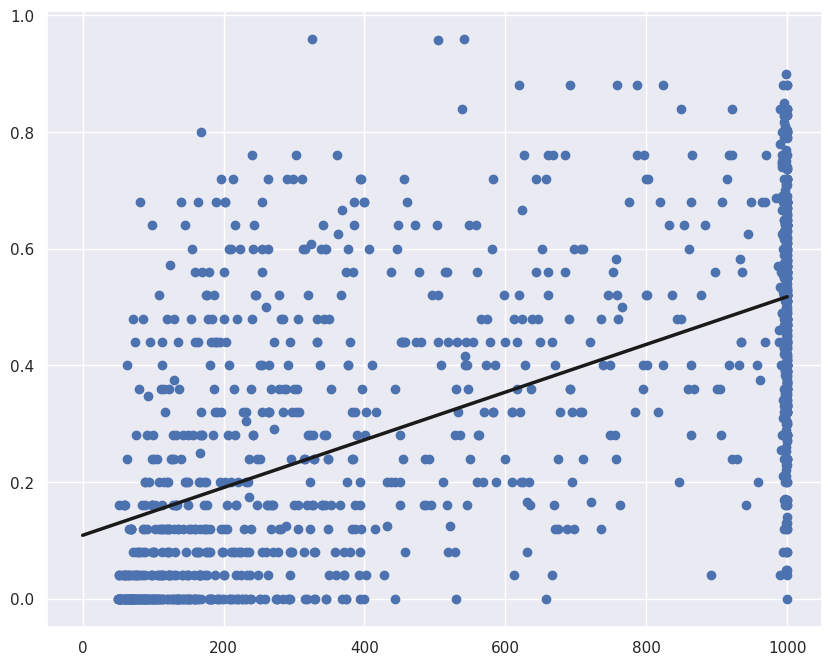

In [65]:
subsets = []
for leaf_class_id in range(num_classes):
    num_train_classes = len(train_cleaned[train_cleaned.leaf_class_id==leaf_class_id])
    subset = results[(results.y == leaf_class_id)]
    subset_acc = (subset.y == subset.yhat).sum() / len(subset)
    subsets.append( (num_train_classes, subset_acc) )

(train_classes, accs) = list(zip(*subsets))
fig, ax = plt.subplots(figsize=(10, 8))
ax.scatter(train_classes, accs)
b_500, a_500 = np.polyfit(train_classes, accs, deg=1)
xseq = np.linspace(0, 1_000, num=100)
ax.plot(xseq, a_500 + b_500 * xseq, color="k", lw=2.5)
plt.show()

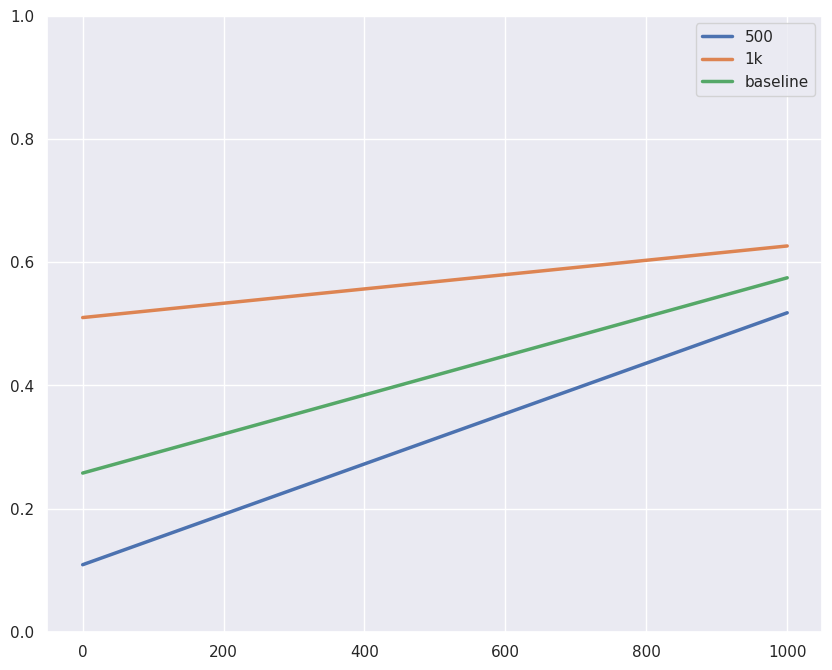

In [66]:
fig, ax = plt.subplots(figsize=(10, 8))

xseq = np.linspace(0, 1_000, num=100)
ax.plot(xseq, a_500 + b_500 * xseq, lw=2.5, label="500")
ax.plot(xseq, a_1k + b_1k * xseq, lw=2.5, label="1k")
ax.plot(xseq, baseline_a + baseline_b * xseq, lw=2.5, label="baseline")


ax.set_ylim([0, 1])

ax.legend()
plt.show()

# ok let's go with augments, baseline first

In [ ]:
wandb.init(project="mammals-new")

baseline_aug_model = make_net(num_classes)
baseline_aug_model.compile(
    loss=loss,
    metrics=["accuracy"],
    optimizer=keras.optimizers.Adam(1e-4),
)

baseline_aug_history = {
    "loss": [],
    "accuracy": [],
    "val_loss": [],
    "val_accuracy": [],
}

NUM_EPOCHS = 10

for epoch in range(NUM_EPOCHS):
    print(f"epoch {epoch+1}/{NUM_EPOCHS}")
    train_cleaned = pd.read_csv(export_dir / "train_cleaned.csv")
    train_cleaned = train_cleaned.sample(frac=1)
    val_cleaned = pd.read_csv(export_dir / "val_cleaned.csv")
    val_cleaned = val_cleaned.sample(frac=1)

    (train_ds, num_train_examples) = make_dataset(train_cleaned, BATCH_SIZE, IMAGE_SIZE, repeat_forever=False, augment=True)
    (val_ds, num_val_examples) = make_dataset(val_cleaned, BATCH_SIZE, IMAGE_SIZE, repeat_forever=False)

    STEPS_PER_EPOCH = int(np.ceil(num_train_examples / BATCH_SIZE))
    VAL_STEPS_PER_EPOCH = int(np.ceil(num_val_examples / BATCH_SIZE))
    
    epoch_hist = baseline_aug_model.fit(
        train_ds,
        steps_per_epoch=STEPS_PER_EPOCH,
        validation_data=val_ds,
        validation_steps=VAL_STEPS_PER_EPOCH,
        epochs=epoch+1,
        initial_epoch=epoch,
        callbacks=[WandbMetricsLogger(log_freq=100)],
    )
    
    baseline_aug_history["loss"].append(epoch_hist.history["loss"][-1])
    baseline_aug_history["accuracy"].append(epoch_hist.history["accuracy"][-1])
    baseline_aug_history["val_loss"].append(epoch_hist.history["val_loss"][-1])
    baseline_aug_history["val_accuracy"].append(epoch_hist.history["val_accuracy"][-1])

wandb.finish()

batch/accuracy,▁▃█
batch/batch_step,▁▅█
batch/learning_rate,▁▁▁
batch/loss,█▃▁
batch/accuracy,0.00187
batch/batch_step,200
batch/learning_rate,0.0001
batch/loss,7.01906


epoch 1/10
3458/5098 [===================>..........] - ETA: 2:49 - loss: 4.8202 - accuracy: 0.1240

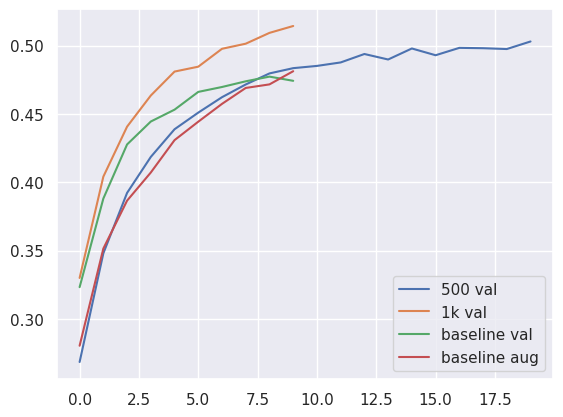

In [71]:
sns.lineplot(history_500["val_accuracy"], label="500 val")
sns.lineplot(history_1k["val_accuracy"], label="1k val")
sns.lineplot(baseline_history["val_accuracy"], label="baseline val")
sns.lineplot(baseline_aug_history["val_accuracy"], label="baseline aug")

plt.legend()
plt.show()

#### eval on test set and get per class metrics

In [72]:
test_preds_baseline_aug = baseline_aug_model.predict(test_ds)
yhats = test_preds_baseline_aug.argmax(axis=1)
ys = test_cleaned["leaf_class_id"].values
results = pd.DataFrame({
    "y": ys,
    "yhat": yhats,
})
(results.y == results.yhat).sum() / len(results)

388/388 [==============================] - 8s 19ms/step


0.4897358931485324

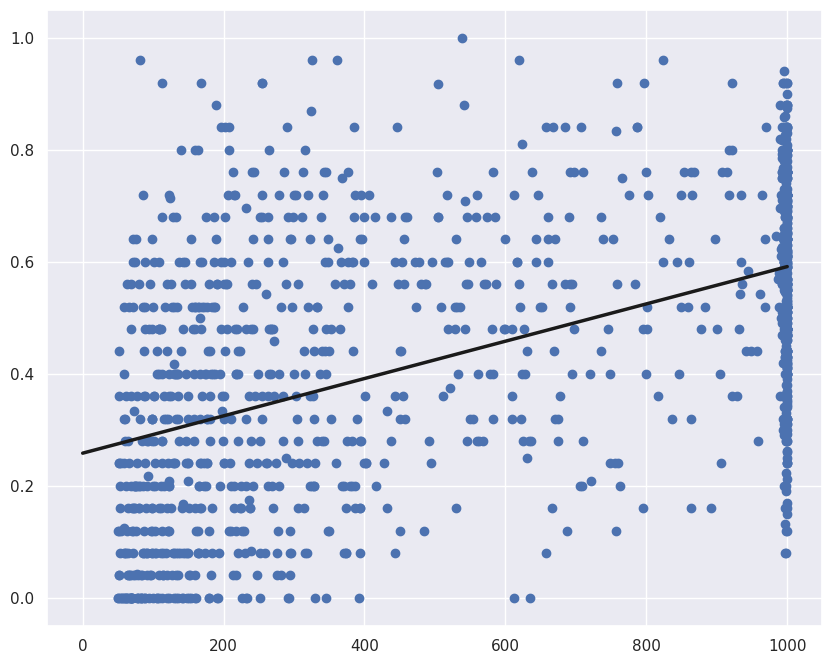

In [73]:
subsets = []
for leaf_class_id in range(num_classes):
    num_train_classes = len(train_cleaned[train_cleaned.leaf_class_id==leaf_class_id])
    subset = results[(results.y == leaf_class_id)]
    subset_acc = (subset.y == subset.yhat).sum() / len(subset)
    subsets.append( (num_train_classes, subset_acc) )

(train_classes, accs) = list(zip(*subsets))
fig, ax = plt.subplots(figsize=(10, 8))
ax.scatter(train_classes, accs)
b_baseline_aug, a_baseline_aug = np.polyfit(train_classes, accs, deg=1)
xseq = np.linspace(0, 1_000, num=100)
ax.plot(xseq, a_baseline_aug + b_baseline_aug * xseq, color="k", lw=2.5)
plt.show()

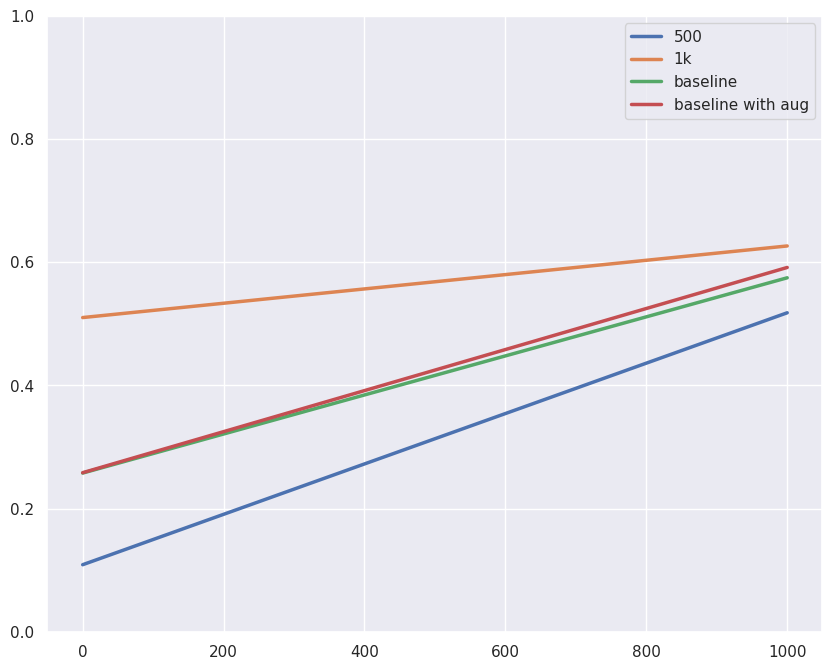

In [74]:
fig, ax = plt.subplots(figsize=(10, 8))

xseq = np.linspace(0, 1_000, num=100)
ax.plot(xseq, a_500 + b_500 * xseq, lw=2.5, label="500")
ax.plot(xseq, a_1k + b_1k * xseq, lw=2.5, label="1k")
ax.plot(xseq, baseline_a + baseline_b * xseq, lw=2.5, label="baseline")
ax.plot(xseq, a_baseline_aug + b_baseline_aug * xseq, lw=2.5, label="baseline with aug")

ax.set_ylim([0, 1])

ax.legend()
plt.show()

# augment with 1k samples

In [ ]:
wandb.init(project="mammals-new")

train_plus_aug_df = pd.concat([train_cleaned, train_augmented])
max_sample_size = 1_000

model_1k_aug = make_net(num_classes)
model_1k_aug.compile(
    loss=loss,
    metrics=["accuracy"],
    optimizer=keras.optimizers.Adam(1e-4),
)

history_1k_aug = {
    "loss": [],
    "accuracy": [],
    "val_loss": [],
    "val_accuracy": [],
}

NUM_EPOCHS = 10
for epoch in range(NUM_EPOCHS):
    print(f"epoch {epoch}")
    
    train_plus_aug_df = train_plus_aug_df.sample(frac=1)
    train_df_sample = train_plus_aug_df.groupby("leaf_class_id").head(max_sample_size)
    train_df_sample = train_df_sample.sample(frac=1)
    
    val_cleaned = pd.read_csv(export_dir / "val_cleaned.csv")
    val_cleaned = val_cleaned.sample(frac=1)
    
    (train_ds, num_train_examples) = make_dataset(train_df_sample, BATCH_SIZE, IMAGE_SIZE, repeat_forever=False, augment=True)
    (val_ds, num_val_examples) = make_dataset(val_cleaned, BATCH_SIZE, IMAGE_SIZE, repeat_forever=False)

    STEPS_PER_EPOCH = int(np.ceil(num_train_examples / BATCH_SIZE))
    VAL_STEPS_PER_EPOCH = int(np.ceil(num_val_examples / BATCH_SIZE))
    
    epoch_hist = model_1k_aug.fit(
        train_ds,
        steps_per_epoch=STEPS_PER_EPOCH,
        validation_data=val_ds,
        validation_steps=VAL_STEPS_PER_EPOCH,
        epochs=epoch+1,
        initial_epoch=epoch,
        callbacks=[WandbMetricsLogger(log_freq=100)],
    )
    history_1k_aug["loss"].append(epoch_hist.history["loss"][-1])
    history_1k_aug["accuracy"].append(epoch_hist.history["accuracy"][-1])
    history_1k_aug["val_loss"].append(epoch_hist.history["val_loss"][-1])
    history_1k_aug["val_accuracy"].append(epoch_hist.history["val_accuracy"][-1])

wandb.finish()

epoch 0
6098/6098 [==============================] - 635s 103ms/step - loss: 4.5147 - accuracy: 0.1452 - val_loss: 3.1851 - val_accuracy: 0.2869
epoch 1
Epoch 2/2
6098/6098 [==============================] - 630s 103ms/step - loss: 3.4964 - accuracy: 0.2593 - val_loss: 2.7626 - val_accuracy: 0.3522
epoch 2
Epoch 3/3
1548/6098 [======>.......................] - ETA: 7:43 - loss: 3.2850 - accuracy: 0.2932

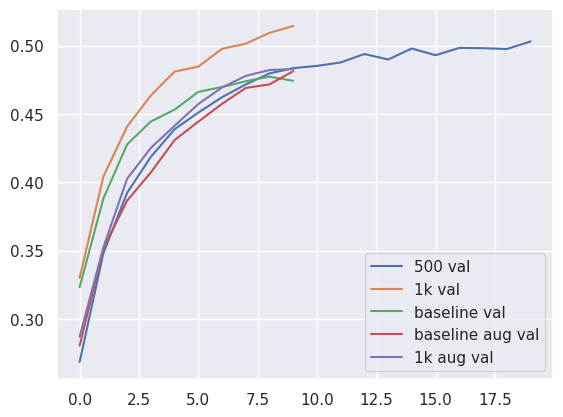

In [77]:
sns.lineplot(history_500["val_accuracy"], label="500 val")
sns.lineplot(history_1k["val_accuracy"], label="1k val")
sns.lineplot(baseline_history["val_accuracy"], label="baseline val")
sns.lineplot(baseline_aug_history["val_accuracy"], label="baseline aug val")
sns.lineplot(history_1k_aug["val_accuracy"], label="1k aug val")

plt.legend()
plt.show()

In [78]:
# eval on test set and get per class samples

test_preds_1k_aug = model_1k_aug.predict(test_ds)
yhats = test_preds_1k_aug.argmax(axis=1)
ys = test_cleaned["leaf_class_id"].values
results = pd.DataFrame({
    "y": ys,
    "yhat": yhats,
})
(results.y == results.yhat).sum() / len(results)

388/388 [==============================] - 8s 19ms/step


0.5033945083502891

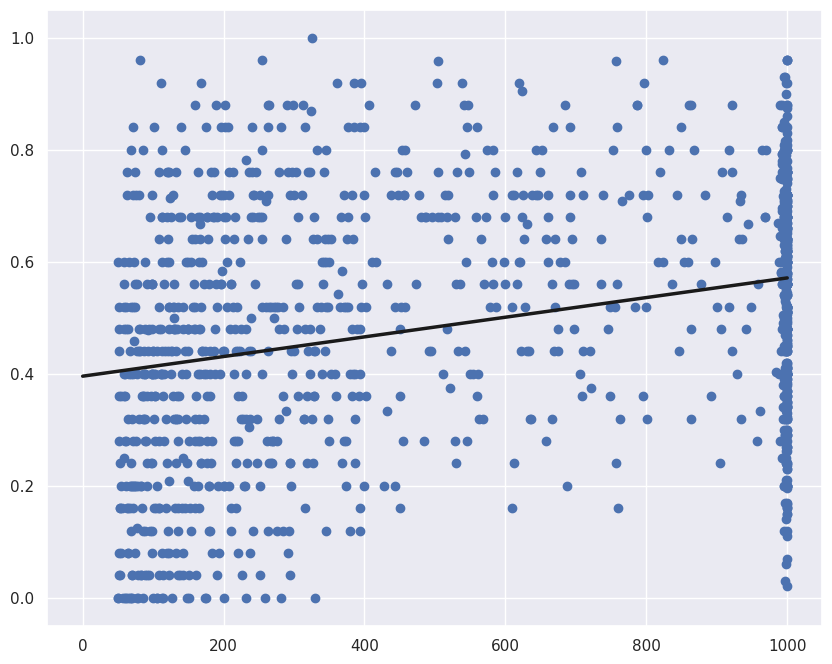

In [79]:
subsets = []
for leaf_class_id in range(num_classes):
    num_train_classes = len(train_cleaned[train_cleaned.leaf_class_id==leaf_class_id])
    subset = results[(results.y == leaf_class_id)]
    subset_acc = (subset.y == subset.yhat).sum() / len(subset)
    subsets.append( (num_train_classes, subset_acc) )

(train_classes, accs) = list(zip(*subsets))
fig, ax = plt.subplots(figsize=(10, 8))
ax.scatter(train_classes, accs)
b_1k_aug, a_1k_aug = np.polyfit(train_classes, accs, deg=1)
xseq = np.linspace(0, 1_000, num=100)
ax.plot(xseq, a_1k_aug + b_1k_aug * xseq, color="k", lw=2.5)
plt.show()

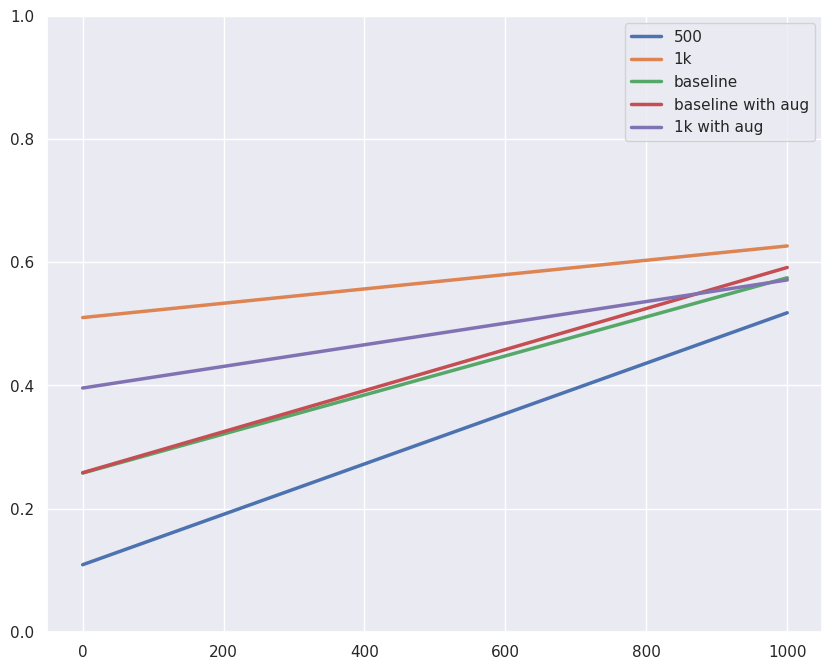

In [80]:
fig, ax = plt.subplots(figsize=(10, 8))

xseq = np.linspace(0, 1_000, num=100)
ax.plot(xseq, a_500 + b_500 * xseq, lw=2.5, label="500")
ax.plot(xseq, a_1k + b_1k * xseq, lw=2.5, label="1k")
ax.plot(xseq, baseline_a + baseline_b * xseq, lw=2.5, label="baseline")
ax.plot(xseq, a_baseline_aug + b_baseline_aug * xseq, lw=2.5, label="baseline with aug")
ax.plot(xseq, a_1k_aug + b_1k_aug * xseq, lw=2.5, label="1k with aug")

ax.set_ylim([0, 1])

ax.legend()
plt.show()

# cos decay?

In [81]:
lr_schedule = keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=0.0,
    decay_steps=900,
    warmup_steps=100,
    warmup_target=1e-4,
)


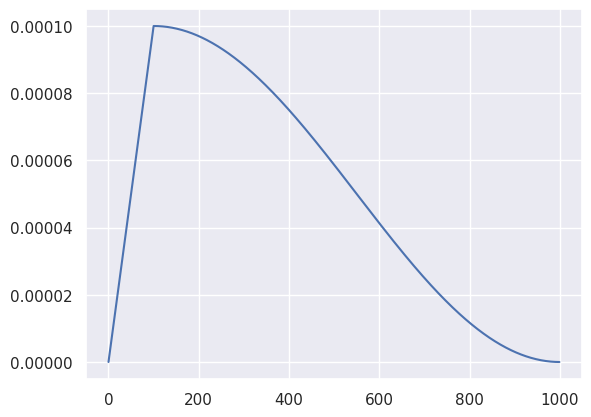

In [83]:
lrs = []

for i in range(1_000):
    lrs.append(lr_schedule(step=i))

plt.plot(lrs)

In [85]:
wandb.init(project="mammals-new")

train_plus_aug_df = pd.concat([train_cleaned, train_augmented])
max_sample_size = 1_000
NUM_EPOCHS = 10

total_steps = STEPS_PER_EPOCH * NUM_EPOCHS
warmup_steps = int(0.1 * total_steps)
decay_steps = total_steps - warmup_steps

decay_steps = STEPS_PER_EPOCH * NUM_EPOCHS
lr_schedule = keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=0.0,
    decay_steps=decay_steps,
    warmup_steps=warmup_steps,
    warmup_target=1e-4,
)

model = make_net(num_classes)
model.compile(
    loss=loss,
    metrics=["accuracy"],
    optimizer=keras.optimizers.Adam(lr_schedule),
)

history_cos_decay = {
    "loss": [],
    "accuracy": [],
    "val_loss": [],
    "val_accuracy": [],
}

for epoch in range(NUM_EPOCHS):
    print(f"epoch {epoch}")
    
    train_plus_aug_df = train_plus_aug_df.sample(frac=1)
    train_df_sample = train_plus_aug_df.groupby("leaf_class_id").head(max_sample_size)
    train_df_sample = train_df_sample.sample(frac=1)
    
    val_cleaned = pd.read_csv(export_dir / "val_cleaned.csv")
    val_cleaned = val_cleaned.sample(frac=1)
    
    (train_ds, num_train_examples) = make_dataset(train_df_sample, BATCH_SIZE, IMAGE_SIZE, repeat_forever=False, augment=True)
    (val_ds, num_val_examples) = make_dataset(val_cleaned, BATCH_SIZE, IMAGE_SIZE, repeat_forever=False)

    STEPS_PER_EPOCH = int(np.ceil(num_train_examples / BATCH_SIZE))
    VAL_STEPS_PER_EPOCH = int(np.ceil(num_val_examples / BATCH_SIZE))
    
    epoch_hist = model.fit(
        train_ds,
        steps_per_epoch=STEPS_PER_EPOCH,
        validation_data=val_ds,
        validation_steps=VAL_STEPS_PER_EPOCH,
        epochs=epoch+1,
        initial_epoch=epoch,
        callbacks=[WandbMetricsLogger(log_freq=100)],
    )
    history_cos_decay["loss"].append(epoch_hist.history["loss"][-1])
    history_cos_decay["accuracy"].append(epoch_hist.history["accuracy"][-1])
    history_cos_decay["val_loss"].append(epoch_hist.history["val_loss"][-1])
    history_cos_decay["val_accuracy"].append(epoch_hist.history["val_accuracy"][-1])

wandb.finish()

epoch 0
6098/6098 [==============================] - 648s 105ms/step - loss: 5.5960 - accuracy: 0.0722 - val_loss: 3.6897 - val_accuracy: 0.2202
epoch 1
Epoch 2/2
6098/6098 [==============================] - 639s 105ms/step - loss: 3.7456 - accuracy: 0.2218 - val_loss: 2.9368 - val_accuracy: 0.3251
epoch 2
Epoch 3/3
6098/6098 [==============================] - 640s 105ms/step - loss: 3.3187 - accuracy: 0.2872 - val_loss: 2.6055 - val_accuracy: 0.3811
epoch 3
Epoch 4/4
6098/6098 [==============================] - 639s 105ms/step - loss: 3.1036 - accuracy: 0.3237 - val_loss: 2.4418 - val_accuracy: 0.4129
epoch 4
Epoch 5/5
6098/6098 [==============================] - 640s 105ms/step - loss: 2.9518 - accuracy: 0.3502 - val_loss: 2.3224 - val_accuracy: 0.4400
epoch 5
Epoch 6/6
6098/6098 [==============================] - 639s 105ms/step - loss: 2.8456 - accuracy: 0.3694 - val_loss: 2.2210 - val_accuracy: 0.4607
epoch 6
Epoch 7/7
6098/6098 [==============================] - 640s 105ms/step -

batch/accuracy,▁▁▁▂▄▄▄▅▅▆▆▆▆▆▆▆▇▇▇▇▇▇▇▇▇▇▇█████████████
batch/batch_step,▂▃▅▇▁▃▅▇▁▃▅▇▂▄▅▇▁▃▅▇▁▃▅▇▂▄▆▇▁▃▅▇▂▄▆█▂▄▆█
batch/learning_rate,▂▃▄▆███████▇▇▇▇▇▆▆▆▆▅▅▅▅▄▄▄▄▃▃▃▂▂▂▂▂▁▁▁▁
batch/loss,██▇▆▃▃▃▃▂▂▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
epoch/accuracy,▁▄▅▆▇▇▇███
epoch/epoch,▁▂▃▃▄▅▆▆▇█
epoch/learning_rate,██▇▇▆▄▃▂▂▁
epoch/loss,█▄▃▂▂▂▁▁▁▁
epoch/val_accuracy,▁▄▅▆▇▇▇███
epoch/val_loss,█▅▃▃▂▂▁▁▁▁
batch/accuracy,0.41152


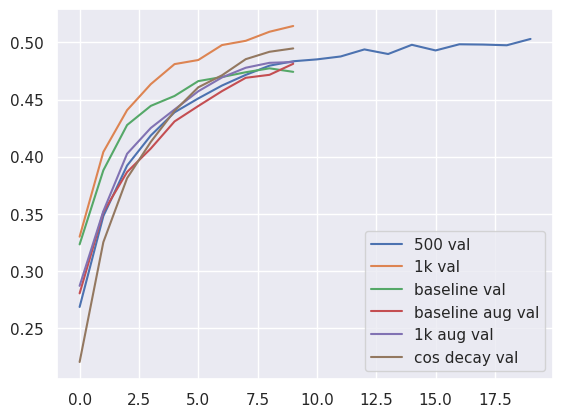

In [86]:
sns.lineplot(history_500["val_accuracy"], label="500 val")
sns.lineplot(history_1k["val_accuracy"], label="1k val")
sns.lineplot(baseline_history["val_accuracy"], label="baseline val")
sns.lineplot(baseline_aug_history["val_accuracy"], label="baseline aug val")
sns.lineplot(history_1k_aug["val_accuracy"], label="1k aug val")
sns.lineplot(history_cos_decay["val_accuracy"], label="cos decay val")

plt.legend()
plt.show()

In [ ]:
# eval on test set and get per class samples

test_preds_1k_aug_cos = model.predict(test_ds)
yhats = test_preds_1k_aug_cos.argmax(axis=1)
ys = test_cleaned["leaf_class_id"].values
results = pd.DataFrame({
    "y": ys,
    "yhat": yhats,
})
(results.y == results.yhat).sum() / len(results)

In [ ]:
subsets = []
for leaf_class_id in range(num_classes):
    num_train_classes = len(train_cleaned[train_cleaned.leaf_class_id==leaf_class_id])
    subset = results[(results.y == leaf_class_id)]
    subset_acc = (subset.y == subset.yhat).sum() / len(subset)
    subsets.append( (num_train_classes, subset_acc) )

(train_classes, accs) = list(zip(*subsets))
fig, ax = plt.subplots(figsize=(10, 8))
ax.scatter(train_classes, accs)
b_1k_aug_cos, a_1k_aug_cos = np.polyfit(train_classes, accs, deg=1)
xseq = np.linspace(0, 1_000, num=100)
ax.plot(xseq, a_1k_aug_cos + b_1k_aug_cos * xseq, color="k", lw=2.5)
plt.show()

In [ ]:
fig, ax = plt.subplots(figsize=(10, 8))

xseq = np.linspace(0, 1_000, num=100)
ax.plot(xseq, a_500 + b_500 * xseq, lw=2.5, label="500")
ax.plot(xseq, a_1k + b_1k * xseq, lw=2.5, label="1k")
ax.plot(xseq, baseline_a + baseline_b * xseq, lw=2.5, label="baseline")
ax.plot(xseq, a_baseline_aug + b_baseline_aug * xseq, lw=2.5, label="baseline with aug")
ax.plot(xseq, a_1k_aug_cos + b_1k_aug_cos * xseq, lw=2.5, label="1k with aug cos")

ax.set_ylim([0, 1])

ax.legend()
plt.show()

# ok let's try a more production like run, more epochs and with wandb integration

In [ ]:
import wandb
from wandb.integration.keras import WandbMetricsLogger

In [ ]:
wandb.init(
    project="galliformes-new"
)

train_plus_aug_df = pd.concat([train_cleaned, train_augmented])
max_sample_size = 1_000
NUM_EPOCHS = 40

total_steps = STEPS_PER_EPOCH * NUM_EPOCHS
warmup_steps = int(0.1 * total_steps)
decay_steps = total_steps - warmup_steps

decay_steps = STEPS_PER_EPOCH * NUM_EPOCHS
lr_schedule = keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=0.0,
    decay_steps=decay_steps,
    warmup_steps=warmup_steps,
    warmup_target=6e-4,
)
optimizer = keras.optimizers.RMSprop(
    learning_rate=lr_schedule,
    rho=0.9,
    momentum=0.9,
    epsilon=1.0e-3,
)

model = make_net(num_classes)
model.compile(
    loss=loss,
    metrics=["accuracy"],
    optimizer=keras.optimizers.Adam(lr_schedule),
)

history = {
    "loss": [],
    "accuracy": [],
    "val_loss": [],
    "val_accuracy": [],
}

for epoch in range(NUM_EPOCHS):
    print(f"epoch {epoch}")
    
    train_plus_aug_df = train_plus_aug_df.sample(frac=1)
    train_df_sample = train_plus_aug_df.groupby("leaf_class_id").head(max_sample_size)
    train_df_sample = train_df_sample.sample(frac=1)
    
    val_cleaned = pd.read_csv(export_dir / "val_cleaned.csv")
    val_cleaned = val_cleaned.sample(frac=1)
    
    (train_ds, num_train_examples) = make_dataset(train_df_sample, BATCH_SIZE, IMAGE_SIZE, repeat_forever=False, augment=True)
    (val_ds, num_val_examples) = make_dataset(val_cleaned, BATCH_SIZE, IMAGE_SIZE, repeat_forever=False)

    STEPS_PER_EPOCH = int(np.ceil(num_train_examples / BATCH_SIZE))
    VAL_STEPS_PER_EPOCH = int(np.ceil(num_val_examples / BATCH_SIZE))
    
    epoch_hist = model.fit(
        train_ds,
        steps_per_epoch=STEPS_PER_EPOCH,
        validation_data=val_ds,
        validation_steps=VAL_STEPS_PER_EPOCH,
        epochs=epoch+1,
        initial_epoch=epoch,
        callbacks=[ WandbMetricsLogger(log_freq=100) ],
    )
    history["loss"].append(epoch_hist.history["loss"][-1])
    history["accuracy"].append(epoch_hist.history["accuracy"][-1])
    history["val_loss"].append(epoch_hist.history["val_loss"][-1])
    history["val_accuracy"].append(epoch_hist.history["val_accuracy"][-1])

wandb.finish()

In [ ]:
wandb.finish()å